In [1]:
import obspy
import math
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime
import re
from obspy.clients.fdsn.client import Client
import json
import scipy
import xarray as xr
from matplotlib.colors import LightSource
import cartopy.crs as ccrs         # to plot maps with different projections
import cartopy.feature as cfeature # to plot coastlines, land, borders, etc.
import json
import matplotlib
from matplotlib import colors
from pyproj import Proj
from geopy.distance import geodesic
import pickle
import matplotlib.animation as animation
matplotlib.rcParams['font.family'] = ['Arial']
plt.rcParams.update({'font.size': 18}) 
from math import radians, cos, sin, atan2, sqrt, degrees
import imageio
from itertools import product
import dask
from dask.diagnostics import ProgressBar
import glob
with open('/Users/zoekrauss/offshore_eew_modeling/location/PB2002_boundaries.json', 'r') as f:
    plate_boundaries = json.load(f)
from pyproj import CRS, Transformer
import re

In [2]:
import xml.etree.ElementTree as ET

In [3]:
def extract_xml(line):
    start = line.find('<')
    end = line.rfind('>')

    if start != -1 and end != -1 and end > start:
        xml_string = line[start:end+1]

    return xml_string

In [4]:
def get_replay_start(filename):
    """
    Read tankplayer log and extract start time
    """
    
    # Read only the first line from the file
    with open(filename, "r") as f:
        for _ in range(10):  # scan up to first 10 lines
            line = f.readline()
            match = re.search(r'UTC_(\d{8})_(\d{2}:\d{2}:\d{2})', line)
            if match:
                date_str = match.group(1)
                time_str = match.group(2)
                utc_time = datetime.datetime.strptime(f"{date_str} {time_str}", "%Y%m%d %H:%M:%S")
                break

    return obspy.UTCDateTime(utc_time)

In [5]:
def read_source_file(filename):
    """
    Read hypocenter lon, lat, and magnitude from Audrey's source text files
    """

    with open(filename,'r') as f:
        lines = f.readlines()

    magnitude = None
    for line in lines:
        if "Hypocenter X:" in line:
            match = re.search(r"X:\s*([\d.]+),\s*Y:\s*([\d.]+)", line)
            if match:
                x = float(match.group(1))
                y = float(match.group(2))
        elif line.startswith("Magnitude:") and magnitude is None:
            match = re.search(r"Magnitude:\s*([\d.]+)", line)
            if match:
                magnitude = float(match.group(1))

    # Hypocenter is given in UTM coordinates. Convert to lat/lon
    utm_crs = CRS.from_epsg(32610)  # EPSG:32610 = WGS84 / UTM zone 10N
    wgs84_crs = CRS.from_epsg(4326)  # WGS84 lat/lon
    # Create transformer
    transformer = Transformer.from_crs(utm_crs, wgs84_crs, always_xy=True)
    lon, lat = transformer.transform(x,y)
    
    return lon,lat,magnitude

In [6]:
def get_xml_blocks(filename):
    """
    Pull out the relevant information from XML log files as separate blocks per each event update
    """
    xml_lines = []
    inside_xml = False
    complete_blocks = []
    
    with open(filename, "r") as file:
        for line in file:
            # if '<event_message alg_vers="3.3.7-2023-11-01" category="live"' in line:
            if '<event_message alg_vers=' in line:
                inside_xml = True
                # add_line = re.findall(r'<.*?>', line.strip()).group()
                add_line = extract_xml(line.strip())
                xml_lines = [add_line]
            elif "</event_message>" in line:
                # add_line = re.search(r'<.*?>', line.strip()).group()
                add_line = extract_xml(line.strip())
                xml_lines.append(add_line)
                inside_xml = False
                xml_string = "".join(xml_lines)
                try:
                    element = ET.fromstring(xml_string)
                    complete_blocks.append(element)
                    # print(f"Parsed block with tag: {element.tag}")
                except ET.ParseError as e:
                    print(f"Error parsing block: {e}")
            elif inside_xml:
                try:
                    add_line = extract_xml(line.strip())
                    # add_line = re.search(r'<.*?>', line.strip()).group()
                    xml_lines.append(add_line)
                except:
                    continue

    return complete_blocks

In [7]:
def get_block_info(block):
    
    """
    Designed to parse one block of a dmevent xml log
    """
    
    # CORE INFO #
    mag = float(block[0][0].text)
    ev_lat = float(block[0][2].text)
    ev_lon = float(block[0][4].text)

    message_time = obspy.UTCDateTime(block.items()[7][1])

    # STATION INFO #
    sta_lats = []
    sta_lons = []
    sta_vals = []
    sta_info = []
    for sta in block[-1][0][0]:
        try: 
            sta_alg = sta.items()[1][1]
        except:
            sta_alg = 'unassoc'
        sta_lats.append(float(sta[2].text))
        sta_lons.append(float(sta[3].text))
        sta_vals.append(float(sta[1].text)) # acceleration in cm/s/s
        sta_chan = sta[0].text.split('.')[2]
        # Get distance between this station and the hypocenter
        sta_dist = geodesic([float(sta[2].text),float(sta[3].text)],[ev_lat,ev_lon]).km
        sta_info.append([float(sta[3].text),float(sta[2].text),float(sta[1].text),sta_dist,sta_alg,sta_chan])

    try:
        for sta in block[-1][0][1]:
            try: 
                sta_alg = sta.items()[1][1]
            except:
                sta_alg = 'unassoc'
            sta_lats.append(float(sta[2].text))
            sta_lons.append(float(sta[3].text))
            sta_vals.append(float(sta[1].text)) # acceleration in cm/s/s
            sta_chan = sta[0].text.split('.')[2]
            # Get distance between this station and the hypocenter
            sta_dist = geodesic([float(sta[2].text),float(sta[3].text)],[ev_lat,ev_lon]).km
            sta_info.append([float(sta[3].text),float(sta[2].text),float(sta[1].text),sta_dist,sta_alg,sta_chan])
    except:
        # print('Only one type of ground motion')
        a=1

    # FAULT INFO, if it exists! #
    vertices = []
    if len(block) > 3:
        for v in block[2][0][0][0]:
            vertices.append([float(v[1].text),float(v[0].text)])
    
        
    block_dict = {'timestamp':message_time,'mag':mag,'ev_lat':ev_lat,'ev_lon':ev_lon,'sta_info':sta_info,'vertices':vertices}

    return block_dict

In [8]:
# filedir = 'japan_subduction/japan_100hz_control_20260820_3/'
#filedir = 'japan_subduction/japan_100hz_control_20260820_3/'
filedir = 'japan_subduction/japan_first10downsampled_control_20260824_2/'
# filedir = 'japan_subduction/japan_first10excluded_20260825_2/'

## Parse and plot results

In [9]:
# Read in true scenario values - lat,lon,mag
# sourcefile_path = '/Users/zoekrauss/offshore_eew_modeling/replays/simulation_sourcefiles/*'
# sourcefile = glob.glob(sourcefile_path+scenario+'*.txt')[0]
# true_ev_lon,true_ev_lat,true_mag = read_source_file(sourcefile)
true_ev_lon = 142.373
true_ev_lat = 38.297
true_mag = 9.1


In [10]:
# Get the time the replay was started, from the tankplayer file
filename = glob.glob(filedir + '**/tankplayer*')[0]
replay_start = get_replay_start(filename)#  + 60    

In [11]:
replay_start

2026-08-24T20:42:55.000000Z

In [12]:
# Get the dmevent info
filename = glob.glob(filedir+'**/dmevent*')[0]
# filename = glob.glob(filedir+'*dmevent*')[0]
complete_blocks = get_xml_blocks(filename)

In [13]:
# Print event IDs to check for split events
for bl in complete_blocks:
    print(bl[0].items()[0][1])

1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604200
1787604190
1787604190
1787604190
1787604190
1787604190
1787604200
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190
1787604190


In [14]:
replay_start

2026-08-24T20:42:55.000000Z

## Mag evolution plots

In [15]:
plt.rcParams.update({'font.size': 14})

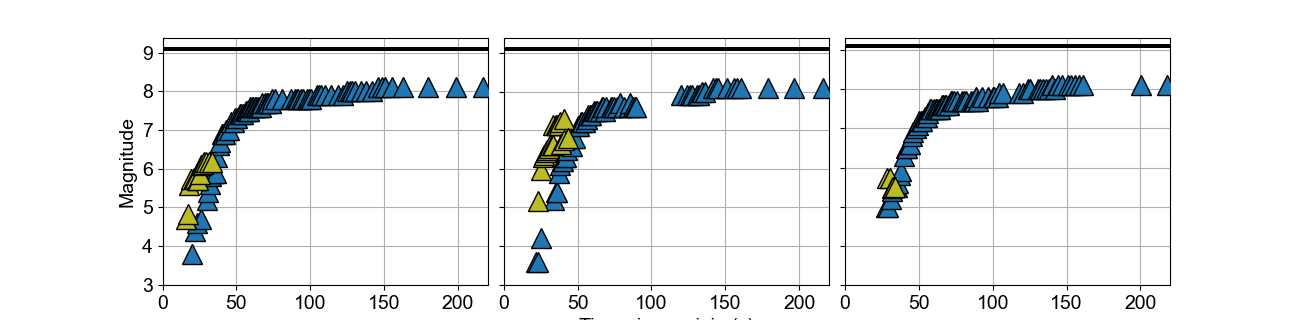

In [16]:
%matplotlib widget

fig,[ax1,ax2,ax3] = plt.subplots(1,3,figsize=[13,  3.2],sharex=True)

# FULL RATE
filedir = 'japan_subduction/japan_100hz_control_20260820_3/'
filename = glob.glob(filedir + '**/tankplayer*')[0]
replay_start = get_replay_start(filename)


# EPIC
filename = glob.glob(filedir+'*/epic_2*')[0]
complete_blocks = get_xml_blocks(filename)
for i,bl in enumerate(complete_blocks):
    block = get_block_info(bl)
    mag_time=block['timestamp']-replay_start
    mag_mag=block['mag']
    if i==0:
        ax1.plot(mag_time,mag_mag,'^',zorder=6,color='tab:olive',markersize=15,markeredgecolor='k',label='Point solution (EPIC)')
    else:
        ax1.plot(mag_time,mag_mag,'^',zorder=6,color='tab:olive',markersize=15,markeredgecolor='k')
    ax1.axhline(true_mag,color='k')
    ax1.grid(True)
    ax1.set_yticks([3,4,5,6,7,8,9])
    ax1.set_ylabel('Magnitude')
    ax1.set_xlim(0,300)

# FinDer
filename = glob.glob(filedir+'*/finder*')[0]
complete_blocks = get_xml_blocks(filename)
for i,bl in enumerate(complete_blocks):
    block = get_block_info(bl)
    mag_time=block['timestamp']-replay_start
    mag_mag=block['mag']
    if i==0:
        ax1.plot(mag_time,mag_mag,'^',zorder=5,color='tab:blue',markersize=15,markeredgecolor='k',label='Fault solution (FinDer)')
    else:
        ax1.plot(mag_time,mag_mag,'^',zorder=5,color='tab:blue',markersize=15,markeredgecolor='k')
    ax1.axhline(true_mag,color='k')
    ax1.grid(True)
    ax1.set_yticks([3,4,5,6,7,8,9])
    ax1.set_ylabel('Magnitude')
    ax1.set_xlim(0,300)

# DOWNSAMPLED
filedir = 'japan_subduction/japan_first10downsampled_control_20260824_2/'
filename = glob.glob(filedir + '**/tankplayer*')[0]
replay_start = get_replay_start(filename)

# EPIC
filename = glob.glob(filedir+'*/epic_2*')[0]
complete_blocks = get_xml_blocks(filename)
for i,bl in enumerate(complete_blocks):
    block = get_block_info(bl)
    mag_time=block['timestamp']-replay_start
    mag_mag=block['mag']
    if i==0:
        ax2.plot(mag_time,mag_mag,'^',zorder=6,color='tab:olive',markersize=15,markeredgecolor='k',label='Point solution (EPIC)')
    else:
        ax2.plot(mag_time,mag_mag,'^',zorder=6,color='tab:olive',markersize=15,markeredgecolor='k')
    ax2.axhline(true_mag,color='k')
    ax2.grid(True)
    ax2.set_yticks([3,4,5,6,7,8,9])
    ax2.set_xlabel('Time since origin (s)')
    ax2.set_xlim(0,300)

# FinDer
filename = glob.glob(filedir+'*/finder*')[0]
complete_blocks = get_xml_blocks(filename)
for i,bl in enumerate(complete_blocks):
    block = get_block_info(bl)
    mag_time=block['timestamp']-replay_start
    mag_mag=block['mag']
    if i==0:
        ax2.plot(mag_time,mag_mag,'^',zorder=5,color='tab:blue',markersize=15,markeredgecolor='k',label='Fault solution (FinDer)')
    else:
        ax2.plot(mag_time,mag_mag,'^',zorder=5,color='tab:blue',markersize=15,markeredgecolor='k')
    ax2.axhline(true_mag,color='k')
    ax2.grid(True)
    ax2.set_yticks([3,4,5,6,7,8,9])
    ax2.set_xlim(0,300)

# EXCLUDED
filedir = 'japan_subduction/japan_first10excluded_20260825_2/'
filename = glob.glob(filedir + '**/tankplayer*')[0]
replay_start = get_replay_start(filename)

# EPIC
filename = glob.glob(filedir+'*/epic_2*')[0]
complete_blocks = get_xml_blocks(filename)
for i,bl in enumerate(complete_blocks):
    block = get_block_info(bl)
    mag_time=block['timestamp']-replay_start
    mag_mag=block['mag']
    if i==0:
        ax3.plot(mag_time,mag_mag,'^',zorder=6,color='tab:olive',markersize=15,markeredgecolor='k',label='Point solution (EPIC)')
    else:
        ax3.plot(mag_time,mag_mag,'^',zorder=6,color='tab:olive',markersize=15,markeredgecolor='k')
    ax3.axhline(true_mag,color='k')
    ax3.grid(True)
    ax3.set_yticks([3,4,5,6,7,8,9])
    ax3.set_xlim(0,300)

# FinDer
filename = glob.glob(filedir+'*/finder*')[0]
complete_blocks = get_xml_blocks(filename)
for i,bl in enumerate(complete_blocks):
    block = get_block_info(bl)
    mag_time=block['timestamp']-replay_start
    mag_mag=block['mag']
    if i==0:
        ax3.plot(mag_time,mag_mag,'^',zorder=5,color='tab:blue',markersize=15,markeredgecolor='k',label='Fault solution (FinDer)')
    else:
        ax3.plot(mag_time,mag_mag,'^',zorder=5,color='tab:blue',markersize=15,markeredgecolor='k')
    ax3.axhline(true_mag,color='k')
    ax3.grid(True)
    ax3.set_yticks([3,4,5,6,7,8,9])
    ax3.set_xlim(0,300)

ax2.set_yticklabels([])
ax3.set_yticklabels([])

plt.subplots_adjust(wspace=0.05, hspace=0.05)

ax1.set_xlim(0,220)
# ax1.legend(loc='lower right')

fig.patch.set_facecolor('none')  # Makes the outer figure background transparent
ax1.patch.set_facecolor('white')  # Keeps the inner axes background solid white
ax2.patch.set_facecolor('white')
ax3.patch.set_facecolor('white')

plt.savefig('/Users/zoekrauss/shakealert_8hz/kona_figs/japan_replayresults.png', dpi=300)

In [26]:
plt.gcf().get_size_inches()

array([11.89,  3.53])

### Static results plot

(0.0, 100.0)

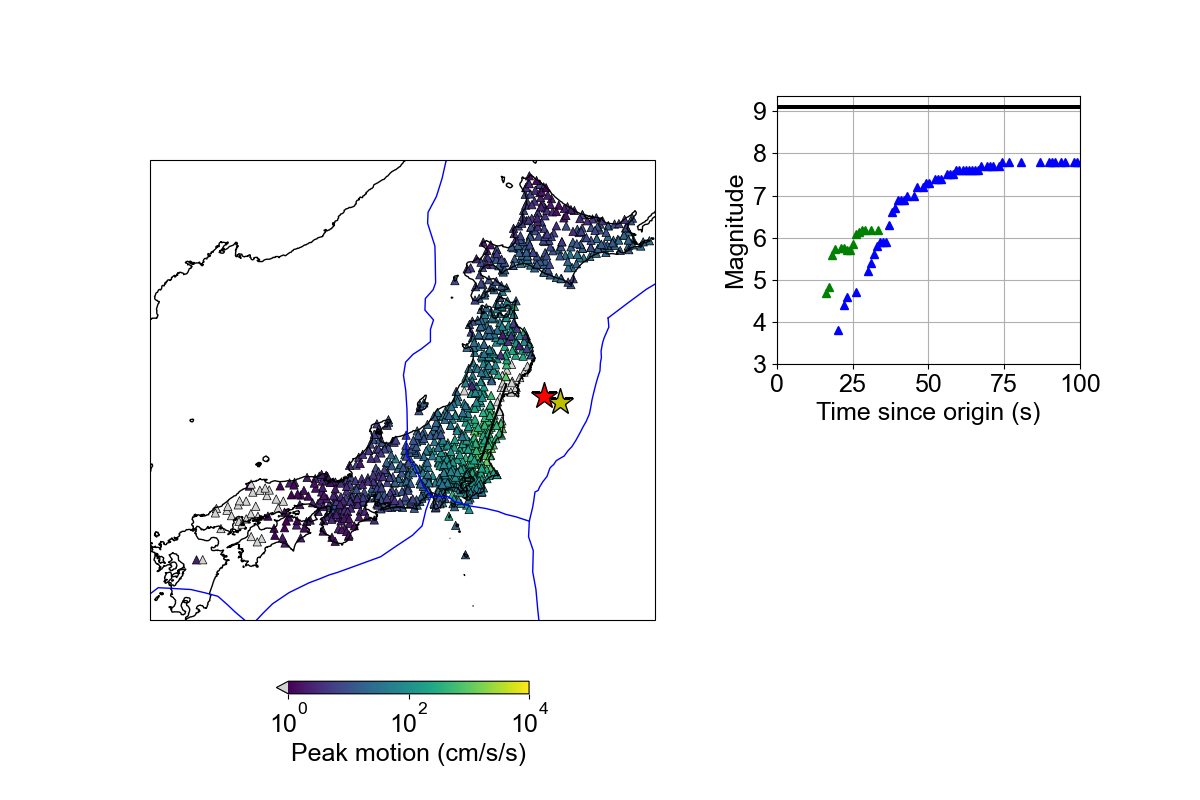

In [303]:
%matplotlib widget

fig = plt.figure(figsize=(12,8))
gs = matplotlib.gridspec.GridSpec(
    nrows=2,
    ncols=2,
    width_ratios=[5,3],     
    height_ratios=[1, 1],    # same height rows, left plot will span both
    wspace=0.3,
    hspace=0.3
)

ax0 = fig.add_subplot(gs[:, 0],projection=ccrs.PlateCarree(central_longitude=0))
ax0.coastlines()
ax1 = fig.add_subplot(gs[0,1])

# EPIC
filename = glob.glob(filedir+'*/epic_2*')[0]
complete_blocks = get_xml_blocks(filename)
for i,bl in enumerate(complete_blocks):
    block = get_block_info(bl)
    mag_time=block['timestamp']-replay_start
    mag_mag=block['mag']
    ax1.plot(mag_time,mag_mag,'g^',zorder=5)
    ax1.axhline(true_mag,color='k')
    ax1.grid(True)
    ax1.set_yticks([3,4,5,6,7,8,9])
    ax1.set_ylabel('Magnitude')
    ax1.set_xlabel('Time since origin (s)')
    ax1.set_xlim(0,300)

# FinDer
filename = glob.glob(filedir+'*/finder*')[0]
complete_blocks = get_xml_blocks(filename)
for i,bl in enumerate(complete_blocks):
    block = get_block_info(bl)
    mag_time=block['timestamp']-replay_start
    mag_mag=block['mag']
    ax1.plot(mag_time,mag_mag,'b^')
    ax1.axhline(true_mag,color='k')
    ax1.grid(True)
    ax1.set_yticks([3,4,5,6,7,8,9])
    ax1.set_ylabel('Magnitude')
    ax1.set_xlabel('Time since origin (s)')
    ax1.set_xlim(0,300)

# DM
filename = glob.glob(filedir+'*/dmevent*')[0]
complete_blocks = get_xml_blocks(filename)
for i,bl in enumerate(complete_blocks):
    block = get_block_info(bl)
    mag_time=block['timestamp']-replay_start
    mag_mag=block['mag']
    # ax1.plot(mag_time,mag_mag,'k^')
    ax1.axhline(true_mag,color='k')
    ax1.grid(True)
    ax1.set_yticks([3,4,5,6,7,8,9])
    ax1.set_ylabel('Magnitude')
    ax1.set_xlabel('Time since origin (s)')
    ax1.set_xlim(0,300)
# Plot final solution origin from DM
block = get_block_info(complete_blocks[-1])
norm = matplotlib.colors.LogNorm(vmin=1, vmax=10000)
cmap = plt.get_cmap('viridis').copy()
cmap.set_under('lightgray')  # color for values below vmin
im = ax0.scatter([b[0] for b in block['sta_info']],[b[1] for b in block['sta_info']],c=[b[2] for b in block['sta_info']],
                 norm=norm,cmap=cmap,marker='^',edgecolor='k',linewidth=0.5)
ax0.plot([b[0] for b in block['vertices']],[b[1] for b in block['vertices']],'k-')
ax0.fill([b[0] for b in block['vertices']],[b[1] for b in block['vertices']],color='gray',alpha=0.5)
ax0.plot(block['ev_lon'],block['ev_lat'],'y*',markersize=20,markeredgecolor='k')
ax0.plot(true_ev_lon,true_ev_lat,'r*',markersize=20,markeredgecolor='k')
# Plot tectonic plate boundaries from local file
for feature in plate_boundaries['features']:
    coords = feature['geometry']['coordinates']
    if feature['geometry']['type'] == 'LineString':
        lons, lats = zip(*coords)
        ax0.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
    elif feature['geometry']['type'] == 'MultiLineString':
        for line in coords:
            lons, lats = zip(*line)
            ax0.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
ax0.set_xlim(129.5,146)
ax0.set_ylim(31,46)
cbar = fig.colorbar(im, ax=ax0, orientation='horizontal', fraction=0.05,shrink=0.5, pad=0.1,extend='min')
cbar.set_label("Peak motion (cm/s/s)")

ax1.set_xlim(0,100)

### Time-varying GIFS, only showing DM

In [304]:
filename = glob.glob(filedir+'*/epic_2*')[0]
complete_blocks = get_xml_blocks(filename)
for bl in complete_blocks:
    print(bl[0].items()[0][1])

1622
1622
1622
1622
1622
1622
1622
1622
1622
1622
1622
1622
1622
1622
1622


/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_68312/3472865697.py:85: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


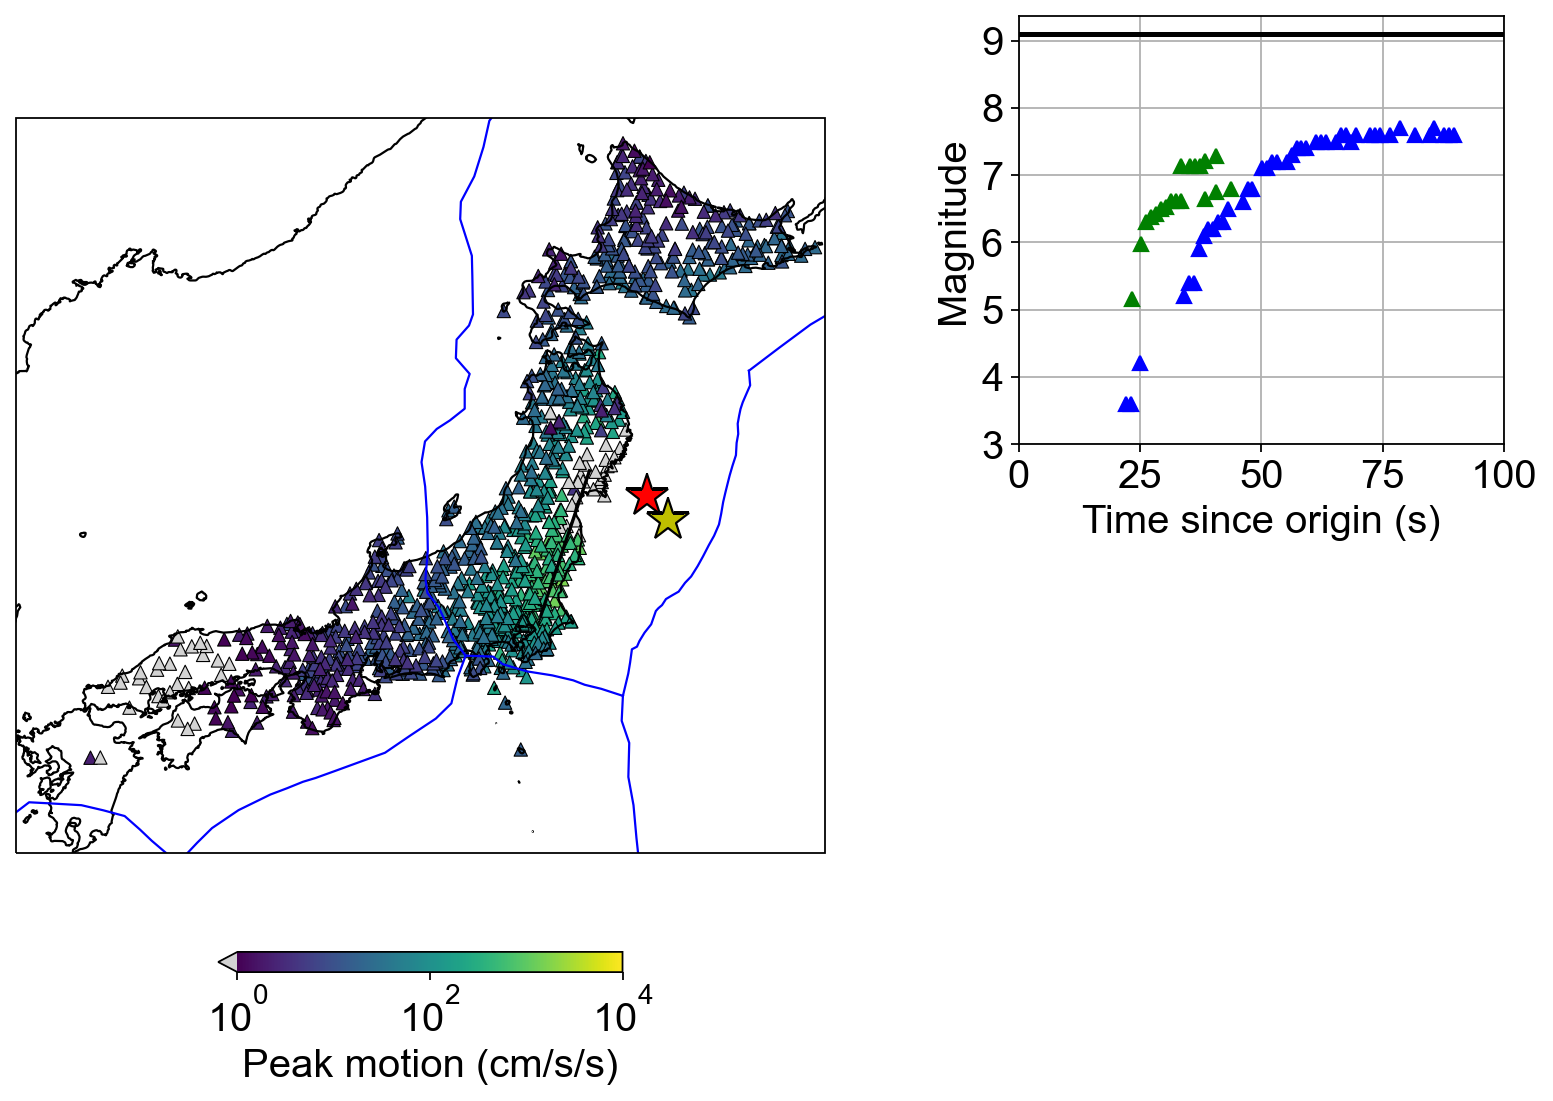

In [291]:
%matplotlib inline

image_files = []

mag_times = []
mag_mags = []
for i,bl in enumerate(complete_blocks):
    fig = plt.figure(figsize=(12,8))
    gs = matplotlib.gridspec.GridSpec(
        nrows=2,
        ncols=2,
        width_ratios=[4,3],     # left column narrower
        height_ratios=[1, 0.8],    # same height rows, left plot will span both
        wspace=0.3,
        hspace=0.3
    )
    
    ax0 = fig.add_subplot(gs[:, 0],projection=ccrs.PlateCarree(central_longitude=0))
    ax0.coastlines()

    block = get_block_info(bl)
    
    # ax0.plot([b[0] for b in block['sta_info']],[b[1] for b in block['sta_info']],'^',markersize=8,markeredgecolor='k',markerfacecolor='gold')
    # norm = matplotlib.colors.LogNorm(vmin=0.001,vmax=10000)
    norm = matplotlib.colors.LogNorm(vmin=1, vmax=10000)
    cmap = plt.get_cmap('viridis').copy()
    cmap.set_under('lightgray')  # color for values below vmin

    im = ax0.scatter([b[0] for b in block['sta_info']],[b[1] for b in block['sta_info']],c=[b[2] for b in block['sta_info']],
                     norm=norm,cmap=cmap,marker='^',edgecolor='k',linewidth=0.5)
    ax0.plot([b[0] for b in block['vertices']],[b[1] for b in block['vertices']],'k-')
    ax0.fill([b[0] for b in block['vertices']],[b[1] for b in block['vertices']],color='gray',alpha=0.5)
    ax0.plot(block['ev_lon'],block['ev_lat'],'y*',markersize=20,markeredgecolor='k')
    
    
    ax0.plot(true_ev_lon,true_ev_lat,'r*',markersize=20,markeredgecolor='k')
    
    # Plot tectonic plate boundaries from local file
    for feature in plate_boundaries['features']:
        coords = feature['geometry']['coordinates']
        if feature['geometry']['type'] == 'LineString':
            lons, lats = zip(*coords)
            ax0.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
        elif feature['geometry']['type'] == 'MultiLineString':
            for line in coords:
                lons, lats = zip(*line)
                ax0.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
    
    ax0.set_xlim(129.5,146)
    ax0.set_ylim(31,46)
    ax0.set_title('Time = '+str(block['timestamp']-replay_start)+' s')

    cbar = fig.colorbar(im, ax=ax0, orientation='horizontal', fraction=0.05, pad=0.1,extend='min')
    cbar.set_label("Peak motion (cm/s/s)")
    
    ax1 = fig.add_subplot(gs[0,1])
    mag_times.append(block['timestamp']-replay_start)
    mag_mags.append(block['mag'])
    ax1.plot(mag_times,mag_mags,'k^')
    ax1.axhline(true_mag,color='k')
    ax1.grid(True)
    ax1.set_yticks([3,4,5,6,7,8,9])
    ax1.set_ylabel('Magnitude')
    ax1.set_xlabel('Time since origin (s)')
    ax1.set_xlim(0,300)
    ax1.set_title('Mag = ' + str(block['mag']))

    ax2 = fig.add_subplot(gs[1,1])
    for b in block['sta_info']:
        if b[-1][2]=='Z':
            ax2.plot([b[3] for b in block['sta_info']],[b[2] for b in block['sta_info']],'k.')
        else:
            ax2.plot([b[3] for b in block['sta_info']],[b[2] for b in block['sta_info']],'b.',alpha=0.5)

    ax2.set_xlim([10,1000])
    ax2.set_xscale('log')
    ax2.set_xticks([10,100,1000])
    ax2.set_ylim([0.001,10000])
    ax2.set_yscale('log')
    ax2.set_yticks([0.001,0.01,0.1,1,10,100,1000])
    ax2.grid(True)
    ax2.set_ylabel('Peak motion (cm/s/s)')
    ax2.set_xlabel('Hypocentral distance (km)')
    
    plt.tight_layout()
        
    # Save as frame for gif
    filename = f'gifs/frame_{i}.png'
    plt.savefig(filename)
    plt.close()
    image_files.append(filename)

In [292]:
# Convert to GIF and clean up
images = []
for filename in image_files:
    images.append(imageio.v2.imread(filename))
imageio.mimsave('gifs/japan_subduction_first10excluded_epic.gif', images,fps=2)

for filename in image_files:
    os.remove(filename)

## More comparison

In [412]:
scenario1 = 'japan_subduction/japan_first10_downsampled_doubleWP_control_20260818_1/'
scenario2 =  'japan_subduction/japan_first10_downsampled_WPedits_20260813_6/'

# scenario1 = 'japan_subduction/japan_first10_downsampled_singleWP_control_20260818_3/'
# scenario2 =  'japan_subduction/japan_first10_downsampled_singleWP_control_20260818_4/'

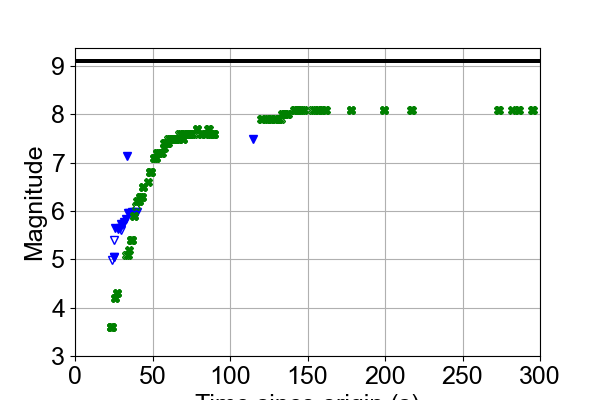

In [413]:
%matplotlib widget

fig,ax1 = plt.subplots(1,figsize=(6,4))

### 
# SCENARIO 1
###

# EPIC
filename = glob.glob(scenario1 + '**/tankplayer*')[0]
replay_start = get_replay_start(filename)    
filename = glob.glob(scenario1+'*/epic_2*')[0]
complete_blocks = get_xml_blocks(filename)
for i,bl in enumerate(complete_blocks):
    block = get_block_info(bl)
    mag_time=block['timestamp']-replay_start
    mag_mag=block['mag']
    if i==0:
        ax1.plot(mag_time,mag_mag,marker='v',markeredgecolor='blue',markerfacecolor='blue',label='EPIC')
    ax1.plot(mag_time,mag_mag,marker='v',markeredgecolor='blue',markerfacecolor='blue')
    ax1.axhline(true_mag,color='k')
    ax1.grid(True)
    ax1.set_yticks([3,4,5,6,7,8,9])
    ax1.set_ylabel('Magnitude')
    ax1.set_xlabel('Time since origin (s)')
    ax1.set_xlim(0,300)

# FinDer
filename = glob.glob(scenario1+'*/finder*')[0]
complete_blocks = get_xml_blocks(filename)
for i,bl in enumerate(complete_blocks):
    block = get_block_info(bl)
    mag_time=block['timestamp']-replay_start
    mag_mag=block['mag']
    if i==0:
        ax1.plot(mag_time,mag_mag,marker='X',markeredgecolor='green',markerfacecolor='green',label='FinDer')
    ax1.plot(mag_time,mag_mag,marker='X',markeredgecolor='green',markerfacecolor='green')
    ax1.axhline(true_mag,color='k')
    ax1.grid(True)
    ax1.set_yticks([3,4,5,6,7,8,9])
    ax1.set_ylabel('Magnitude')
    ax1.set_xlabel('Time since origin (s)')
    ax1.set_xlim(0,300)

# # DM
# filename = glob.glob(scenario1+'*/dmevent*')[0]
# complete_blocks = get_xml_blocks(filename)
# for i,bl in enumerate(complete_blocks):
#     block = get_block_info(bl)
#     mag_time=block['timestamp']-replay_start
#     mag_mag=block['mag']
#     if i==0:
#         ax1.plot(mag_time,mag_mag,marker='s',markeredgecolor='k',markerfacecolor='k',markersize=4,label='DM')
#     ax1.plot(mag_time,mag_mag,marker='s',markeredgecolor='k',markerfacecolor='k',markersize=6)
#     ax1.axhline(true_mag,color='k')
#     ax1.grid(True)
#     ax1.set_yticks([3,4,5,6,7,8,9])
#     ax1.set_ylabel('Magnitude')
#     ax1.set_xlabel('Time since origin (s)')
#     ax1.set_xlim(0,300)

# ax1.legend()
### 
# SCENARIO 2
###

# EPIC
filename = glob.glob(scenario2 + '**/tankplayer*')[0]
replay_start = get_replay_start(filename)    
filename = glob.glob(scenario2+'*/epic_2*')[0]
complete_blocks = get_xml_blocks(filename)
for i,bl in enumerate(complete_blocks):
    block = get_block_info(bl)
    mag_time=block['timestamp']-replay_start
    mag_mag=block['mag']
    ax1.plot(mag_time,mag_mag,marker='v',markeredgecolor='blue',markerfacecolor='None')
    ax1.axhline(true_mag,color='k')
    ax1.grid(True)
    ax1.set_yticks([3,4,5,6,7,8,9])
    ax1.set_ylabel('Magnitude')
    ax1.set_xlabel('Time since origin (s)')
    ax1.set_xlim(0,300)

# FinDer
filename = glob.glob(scenario2+'*/finder*')[0]
complete_blocks = get_xml_blocks(filename)
for i,bl in enumerate(complete_blocks):
    block = get_block_info(bl)
    mag_time=block['timestamp']-replay_start
    mag_mag=block['mag']
    ax1.plot(mag_time,mag_mag,marker='X',markeredgecolor='green',markerfacecolor='None')
    ax1.axhline(true_mag,color='k')
    ax1.grid(True)
    ax1.set_yticks([3,4,5,6,7,8,9])
    ax1.set_ylabel('Magnitude')
    ax1.set_xlabel('Time since origin (s)')
    ax1.set_xlim(0,300)

# DM
# filename = glob.glob(scenario2+'*/dmevent*')[0]
# complete_blocks = get_xml_blocks(filename)
# for i,bl in enumerate(complete_blocks):
#     block = get_block_info(bl)
#     mag_time=block['timestamp']-replay_start
#     mag_mag=block['mag']
#     ax1.plot(mag_time,mag_mag,marker='s',markeredgecolor='k',markerfacecolor='None',markersize=6)
#     ax1.axhline(true_mag,color='k')
#     ax1.grid(True)
#     ax1.set_yticks([3,4,5,6,7,8,9])
#     ax1.set_ylabel('Magnitude')
#     ax1.set_xlabel('Time since origin (s)')
#     ax1.set_xlim(0,300)


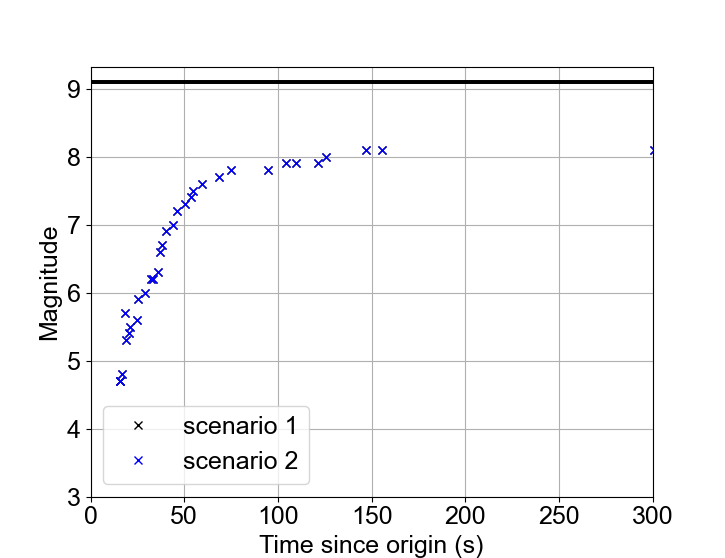

In [347]:
# Just compare the DM
%matplotlib widget

fig,ax1 = plt.subplots(1,figsize=[7.25, 5.58])

### 
# SCENARIO 1
###

# DM
filename = glob.glob(scenario1 + '**/tankplayer*')[0]
replay_start = get_replay_start(filename)  
filename = glob.glob(scenario1+'*/dmevent*')[0]
complete_blocks = get_xml_blocks(filename)
for i,bl in enumerate(complete_blocks):
    block = get_block_info(bl)
    mag_time=block['timestamp']-replay_start
    mag_mag=block['mag']
    if i==0:
        ax1.plot(mag_time,mag_mag,'kx',label='scenario 1')
    ax1.plot(mag_time,mag_mag,'kx')
    ax1.axhline(true_mag,color='k')
    ax1.grid(True)
    ax1.set_yticks([3,4,5,6,7,8,9])
    ax1.set_ylabel('Magnitude')
    ax1.set_xlabel('Time since origin (s)')
    ax1.set_xlim(0,300)

### 
# SCENARIO 2
###

# DM
filename = glob.glob(scenario2 + '**/tankplayer*')[0]
replay_start = get_replay_start(filename)  
filename = glob.glob(scenario2+'*/dmevent*')[0]
complete_blocks = get_xml_blocks(filename)
for i,bl in enumerate(complete_blocks):
    block = get_block_info(bl)
    mag_time=block['timestamp']-replay_start
    mag_mag=block['mag']
    if i==0:
        ax1.plot(mag_time,mag_mag,'bx',label='scenario 2')
    ax1.plot(mag_time,mag_mag,'bx')
    ax1.axhline(true_mag,color='k')
    ax1.grid(True)
    ax1.set_yticks([3,4,5,6,7,8,9])
    ax1.set_ylabel('Magnitude')
    ax1.set_xlabel('Time since origin (s)')
    ax1.set_xlim(0,300)

ax1.legend()

In [207]:
plt.gcf().get_size_inches()

array([7.25, 5.58])